# Regression: predicting the nightly price of NYC Airbnb listings

**What this notebook does**
1. Learns what a listing normally costs from **similar listings** (same room type, similar location, similar minimum stay).
2. Gives **every listing a predicted price**, made by a model that never saw that listing or its host.
3. Saves the predictions in `data/processed/predictions.csv` for step 3 (Dragos), who compares actual and predicted prices by host type.

**Three models are compared**
| Model | How it guesses the price |
|---|---|
| Baseline | Median price of listings with the same `neighbourhood_group` and room type |
| Linear regression (ordinary least squares) | A weighted sum of the inputs |
| Tree model (gradient boosting) | Many small decision trees, each correcting the previous ones |

The main measure is **MAE** (mean absolute error): on average, how many dollars the predicted price is away from the actual price. Lower is better.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold, KFold, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, PowerTransformer, StandardScaler
from scipy.stats import loguniform, randint

SEED = 42   # fixed, so every run gives the same numbers

# Chart style: one colour per series, light grid, values written on the charts
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#b4b2a9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d6d4cd", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

## 2. Load the data and choose the inputs
The cleaned listings come from the cleaning notebook (`02_data_cleaning.ipynb`): 48,870 listings, one row each.

- **Target** (what we predict): `price`, in USD per night.
- **Inputs** (what the model uses): facts about the listing and its location.

| Used as inputs | Not used, and why |
|---|---|
| `room_type`, `neighbourhood_group`, `dist_midtown_km`, `latitude`, `longitude`, `minimum_nights` | `availability_365`, `zero_availability`, `calculated_host_listings_count`: they describe how the host operates, and the host types are built from them (agreed 8 Nov) |
| | Review columns: kept for the comparison after modelling |
| | `price_above_1000`: made from the price itself |
| | `neighbourhood`: many neighbourhoods have too few listings |

Whether `minimum_nights` stays in is still to be confirmed by the team.

In [2]:
local_path = Path("../data/processed/listings_clean.csv")
url = "https://raw.githubusercontent.com/aabouraya/airbnb-nyc-pricing-segments/refs/heads/main/data/processed/listings_clean.csv"
df = pd.read_csv(local_path if local_path.exists() else url)

# Sonder (one company) uses two host IDs: treat them as one host for the split in section 4
SONDER_IDS = [219517861, 12243051]
df["host_group"] = df["host_id"].where(~df["host_id"].isin(SONDER_IDS), SONDER_IDS[0])

CATEGORICAL = ["neighbourhood_group", "room_type"]
NUMERIC = ["dist_midtown_km", "minimum_nights", "latitude", "longitude"]
FEATURES = CATEGORICAL + NUMERIC

X = df[FEATURES]
y = df["price"]
groups = df["host_group"]

print(len(df), "listings from", df["host_id"].nunique(), "hosts")
X.head()

48870 listings from 37442 hosts


,neighbourhood_group,room_type,dist_midtown_km,minimum_nights,latitude,longitude
0,Brooklyn,Private room,12.434392,1,40.64749,-73.97237
1,Manhattan,Entire home/apt,0.597744,1,40.75362,-73.98377
2,Manhattan,Private room,6.656715,3,40.80902,-73.94190
3,Brooklyn,Entire home/apt,8.475391,1,40.68514,-73.95976
4,Manhattan,Entire home/apt,5.603787,10,40.79851,-73.94399


## 3. Why the models learn the log of the price
Most listings cost between USD 50 and 250, but a few cost up to USD 10,000. Models try to make their **squared** errors small, so these few listings would pull every prediction up. Taking the **log** of the price squeezes the high prices together, so all listings count more evenly. Predictions are converted back to dollars afterwards.

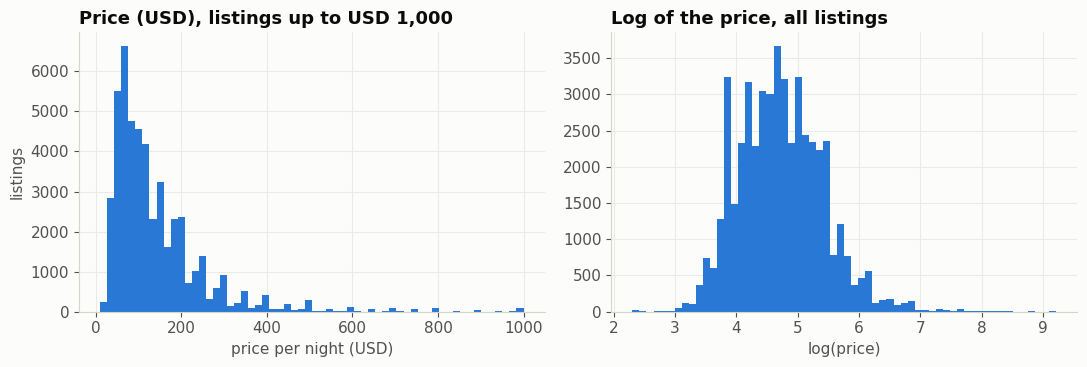

Median price: USD 106.0 | listings above USD 1,000: 239


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(y[y <= 1000], bins=60, color=BLUE)
axes[0].set_title("Price (USD), listings up to USD 1,000")
axes[0].set_xlabel("price per night (USD)"); axes[0].set_ylabel("listings")
axes[1].hist(np.log(y), bins=60, color=BLUE)
axes[1].set_title("Log of the price, all listings")
axes[1].set_xlabel("log(price)")
plt.tight_layout(); plt.show()
print("Median price: USD", y.median(), "| listings above USD 1,000:", int((y > 1000).sum()))

**Finding:** the price is strongly skewed to the right (left chart; 239 listings above USD 1,000 are not even shown). The log of the price is roughly bell-shaped (right chart), which suits the models much better.

## 4. Fair testing: cross-validation split by host
A model must be tested on listings it has **not** seen. **Cross-validation** does this five times: split the listings into 5 parts (folds), train on 4, predict the 5th, and repeat until every listing has one prediction.

All listings of a host stay in the **same fold** (`GroupKFold`). Listings of the same host are often near-copies, so otherwise the model would partly recognise them instead of predicting them.

In [4]:
folds = list(GroupKFold(n_splits=5).split(X, y, groups))

df["fold"] = -1
for i, (train_idx, test_idx) in enumerate(folds):
    df.loc[test_idx, "fold"] = i

print("Listings per fold:", df["fold"].value_counts().sort_index().tolist())
print("Hosts in more than one fold:", int((df.groupby("host_group")["fold"].nunique() > 1).sum()))

Listings per fold: [9774, 9774, 9774, 9774, 9774]
Hosts in more than one fold: 0


Every model is measured in the same way, on all listings, against their actual prices:
- **MAE**: average error in USD (main measure);
- **typical error**: the error of the middle listing (median), not affected by extreme prices;
- **R² (log scale)**: the share of the relative price differences the model explains (0 = nothing, 1 = everything).

In [5]:
results, predictions = {}, {}

def evaluate(name, pred):
    predictions[name] = pred
    results[name] = {
        "MAE (USD)": mean_absolute_error(y, pred),
        "typical error (USD)": np.median(np.abs(y - pred)),
        "R² (log scale)": r2_score(np.log(y), np.log(pred)),
    }
    return pd.Series(results[name]).round(2)

def out_of_fold(model, inputs=None):
    """Train on 4 folds, predict the 5th, for each of the 5 folds."""
    return cross_val_predict(model, X if inputs is None else inputs, y, groups=groups, cv=folds)

## 5. Model 1: Baseline
The simplest sensible guess: **the median price of listings with the same `neighbourhood_group` and room type** (for example, all private rooms in Brooklyn get USD 65). A model only counts if it beats this.

The medians are learned from the training folds only, like a real model (`fit` = calculate the medians, `predict` = look them up).

In [6]:
class MedianBaseline(BaseEstimator, RegressorMixin):
    def fit(self, X, y):
        self.medians_ = pd.Series(np.asarray(y), index=pd.MultiIndex.from_frame(X[CATEGORICAL])).groupby(level=[0, 1]).median()
        self.overall_median_ = float(np.median(y))   # used if a combination is missing
        return self

    def predict(self, X):
        keys = pd.MultiIndex.from_frame(X[CATEGORICAL])
        return self.medians_.reindex(keys).fillna(self.overall_median_).to_numpy()

evaluate("Baseline", out_of_fold(MedianBaseline()))

MAE (USD)              64.68
typical error (USD)    30.00
R² (log scale)          0.45
dtype: float64

## 6. Model 2: Linear regression (ordinary least squares)
The price is predicted as a **weighted sum** of the inputs, on the log scale:

> log(price) = start + weight × (private room?) + weight × (Brooklyn?) + … + weight × log(distance) + …

Training finds the weights with the smallest squared errors. Before that, the inputs are prepared inside a `Pipeline` (refitted in every fold):
- room type and `neighbourhood_group` become yes/no columns, compared with an **entire home in Manhattan**;
- distance and minimum stay are log-transformed, as their effect levels off;
- numeric inputs are scaled, so their weights are comparable.

In [7]:
linear = TransformedTargetRegressor(
    regressor=Pipeline([
        ("prep", ColumnTransformer([
            ("categories", OneHotEncoder(drop=["Manhattan", "Entire home/apt"], handle_unknown="ignore"), CATEGORICAL),
            ("log_then_scale", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                         ("scale", StandardScaler())]), ["dist_midtown_km", "minimum_nights"]),
            ("scale", StandardScaler(), ["latitude", "longitude"]),
        ])),
        ("model", LinearRegression()),
    ]),
    func=np.log, inverse_func=np.exp)

evaluate("Linear regression", out_of_fold(linear))

MAE (USD)              62.96
typical error (USD)    27.21
R² (log scale)          0.50
dtype: float64

**What the linear model learns.** As it works on the log of the price, each weight is a percentage change. The chart shows the categories, compared with an entire home in Manhattan, holding distance and the other inputs the same (model trained on all listings, for explanation only).

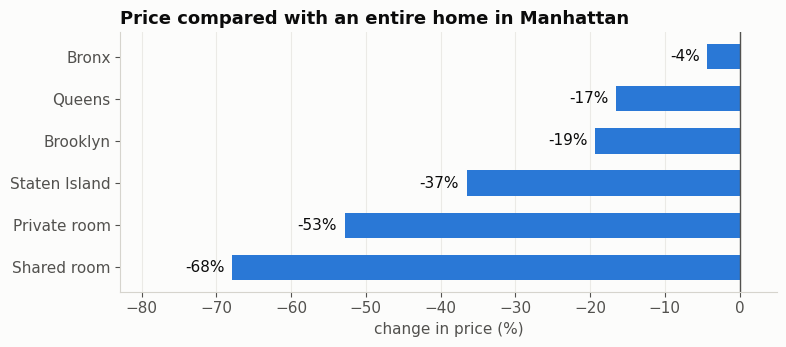

In [8]:
fitted_linear = linear.fit(X, y)
names = fitted_linear.regressor_.named_steps["prep"].get_feature_names_out()
weights = pd.Series(fitted_linear.regressor_.named_steps["model"].coef_, index=names)
effects = ((np.exp(weights[[n for n in names if n.startswith("categories__")]]) - 1) * 100).sort_values()
effects.index = [n.split("_", 4)[-1].replace("group_", "").replace("type_", "") for n in effects.index]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(effects.index, effects.values, color=BLUE, height=0.6)
for i, v in enumerate(effects.values):
    ax.text(v - 1, i, f"{v:.0f}%", va="center", ha="right", color="#0b0b0b")
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlim(effects.min() - 15, 5)
ax.set_title("Price compared with an entire home in Manhattan")
ax.set_xlabel("change in price (%)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Finding:** room type has the biggest effect: private rooms are about 53% cheaper than entire homes, shared rooms about 68%. Listings outside Manhattan are cheaper (Staten Island most), on top of the distance effect. The location inputs overlap, so the borough percentages should be read as a rough picture.

## 7. Model 3: Tree model (gradient boosting)
A **decision tree** predicts with yes/no questions ("Entire home? → Within 5 km of Times Square? → …"). **Gradient boosting** builds hundreds of small trees, each one correcting the errors of the trees before it. It finds curves and combinations by itself, so the inputs need no log or scaling.

**Tuning:** the model's settings (how big each tree is, how carefully it learns) and the price transformation (log, or **Box-Cox**, a stronger version of the log) are chosen automatically. To keep the test fair, they are chosen **inside the 4 training folds only** (with 3 inner folds, grouped by host), and only then is the 5th fold predicted.

In [9]:
tree = TransformedTargetRegressor(
    regressor=Pipeline([
        ("prep", ColumnTransformer([("categories", OrdinalEncoder(), CATEGORICAL)], remainder="passthrough")),
        ("model", HistGradientBoostingRegressor(categorical_features=[0, 1], max_iter=500, random_state=SEED)),
    ]),
    transformer=FunctionTransformer(np.log, inverse_func=np.exp, check_inverse=False))

settings_to_try = {
    "transformer": [FunctionTransformer(np.log, inverse_func=np.exp, check_inverse=False),
                    PowerTransformer(method="box-cox", standardize=False)],
    "regressor__model__learning_rate": loguniform(0.02, 0.2),
    "regressor__model__max_leaf_nodes": randint(15, 128),
    "regressor__model__min_samples_leaf": randint(10, 200),
    "regressor__model__l2_regularization": loguniform(1e-3, 10),
}

pred_tree = np.zeros(len(y))
tuned_models = []
for train_idx, test_idx in folds:
    search = RandomizedSearchCV(tree, settings_to_try, n_iter=30, cv=GroupKFold(n_splits=3),
                                scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=-1)
    search.fit(X.iloc[train_idx], y.iloc[train_idx], groups=groups.iloc[train_idx])
    pred_tree[test_idx] = search.predict(X.iloc[test_idx])
    tuned_models.append(search)

evaluate("Tree model (gradient boosting)", pred_tree)

MAE (USD)              60.65
typical error (USD)    25.35
R² (log scale)          0.54
dtype: float64

In [10]:
pd.DataFrame([{
    "fold": i,
    "price transformation": "Box-Cox" if isinstance(s.best_params_["transformer"], PowerTransformer) else "log",
    "learning rate": round(s.best_params_["regressor__model__learning_rate"], 3),
    "groups per tree": s.best_params_["regressor__model__max_leaf_nodes"],
    "min. listings per group": s.best_params_["regressor__model__min_samples_leaf"],
    "trees used": s.best_estimator_.regressor_.named_steps["model"].n_iter_,
} for i, s in enumerate(tuned_models)]).set_index("fold")

,price transformation,learning rate,groups per tree,min. listings per group,trees used
fold,,,,,
0,Box-Cox,0.021,103,69,425
1,Box-Cox,0.037,67,33,177
2,Box-Cox,0.105,44,47,119
3,Box-Cox,0.037,67,33,202
4,Box-Cox,0.024,85,18,373


**How to read it:** the settings chosen in each of the 5 rounds. Box-Cox was preferred over the log in every round.

## 8. Comparing the three models

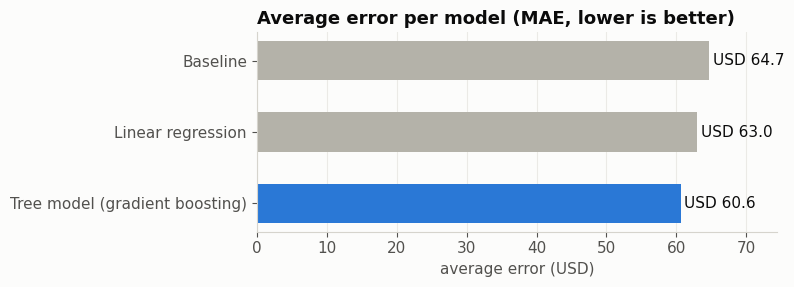

,MAE (USD),typical error (USD),R² (log scale)
Baseline,64.68,30.00,0.45
Linear regression,62.96,27.21,0.50
Tree model (gradient boosting),60.65,25.35,0.54


In [11]:
comparison = pd.DataFrame(results).T
fig, ax = plt.subplots(figsize=(8, 3))
colors = [BLUE if name == comparison["MAE (USD)"].idxmin() else GRAY for name in comparison.index]
ax.barh(comparison.index[::-1], comparison["MAE (USD)"][::-1], color=colors[::-1], height=0.55)
for i, v in enumerate(comparison["MAE (USD)"][::-1]):
    ax.text(v + 0.5, i, f"USD {v:.1f}", va="center", color="#0b0b0b")
ax.set_xlim(0, comparison["MAE (USD)"].max() * 1.15)
ax.set_title("Average error per model (MAE, lower is better)")
ax.set_xlabel("average error (USD)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
comparison.round(2)

**Finding:** the tree model (gradient boosting) is the most accurate, about USD 4 better than the baseline on average, and a typical listing is about USD 25 away instead of USD 30. The gain is modest: room type and location already explain most of what these inputs can explain. The rest of the price depends on things the data does not contain (size, photos, quality), so gaps should be read as "above or below the model's estimate", not as mispricing.

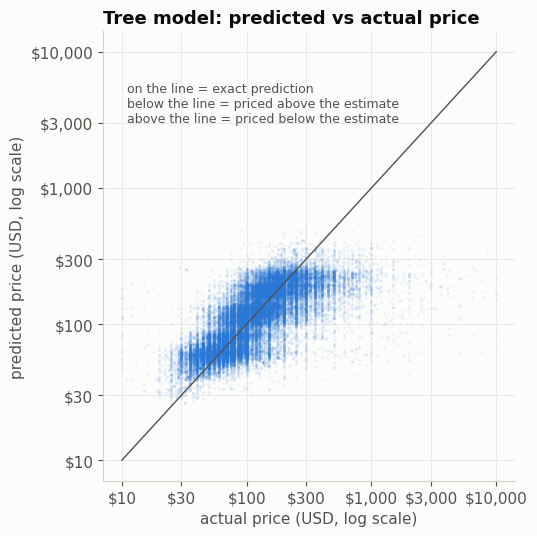

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y, pred_tree, s=4, alpha=0.08, color=BLUE, linewidths=0)
ax.plot([10, 10000], [10, 10000], color="#52514e", linewidth=1)
ax.set_xscale("log"); ax.set_yscale("log")
ticks = [10, 30, 100, 300, 1000, 3000, 10000]
ax.set_xticks(ticks, [f"${t:,}" for t in ticks]); ax.set_yticks(ticks, [f"${t:,}" for t in ticks])
ax.minorticks_off()
ax.set_xlabel("actual price (USD, log scale)"); ax.set_ylabel("predicted price (USD, log scale)")
ax.set_title("Tree model: predicted vs actual price")
ax.text(11, 6000, "on the line = exact prediction\nbelow the line = priced above the estimate\nabove the line = priced below the estimate",
        fontsize=9, color="#52514e", va="top")
plt.tight_layout(); plt.show()

**How to read it:** each dot is a listing. Predictions stay between about USD 40 and 400, while actual prices range from USD 10 to 10,000: the model is cautious and pulls extreme listings towards the typical price for their kind. The largest gaps for step 3 are therefore at the extremes.

## 9. What explains prices
**Permutation importance:** shuffle one input in the test fold (so it no longer carries information) and see how much the error grows. The location inputs overlap, so they are shuffled together as one group.

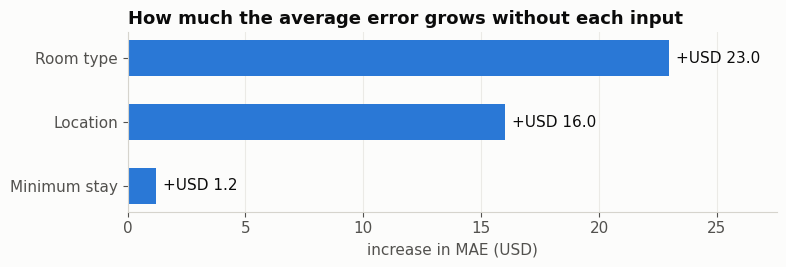

In [13]:
INPUT_GROUPS = {
    "Room type": ["room_type"],
    "Location": ["neighbourhood_group", "dist_midtown_km", "latitude", "longitude"],
    "Minimum stay": ["minimum_nights"],
}
rng = np.random.default_rng(SEED)
rows = []
for (train_idx, test_idx), model in zip(folds, tuned_models):
    X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
    base_mae = mean_absolute_error(y_test, model.predict(X_test))
    for group, cols in INPUT_GROUPS.items():
        for repeat in range(3):
            shuffled, order = X_test.copy(), rng.permutation(len(X_test))
            for c in cols:
                shuffled[c] = X_test[c].to_numpy()[order]
            rows.append({"input": group, "increase": mean_absolute_error(y_test, model.predict(shuffled)) - base_mae})
importance = pd.DataFrame(rows).groupby("input")["increase"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(importance.index, importance.values, color=BLUE, height=0.55)
for i, v in enumerate(importance.values):
    ax.text(v + 0.3, i, f"+USD {v:.1f}", va="center", color="#0b0b0b")
ax.set_xlim(0, importance.max() * 1.2)
ax.set_title("How much the average error grows without each input")
ax.set_xlabel("increase in MAE (USD)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Finding:** room type matters most (without it, the average error grows by about USD 23), then location (about USD 16). Minimum stay matters little for accuracy (about USD 1).

## 10. Handover file for step 3
One row per listing, in the format proposed in the working plan (section 4, step 2). `pred_tree` is the main prediction for the gaps.

In [14]:
handover = df[["id", "host_id", "price", "fold"]].assign(
    pred_baseline=predictions["Baseline"],
    pred_linear=predictions["Linear regression"],
    pred_tree=predictions["Tree model (gradient boosting)"],
)
out_path = Path("../data/processed/predictions.csv")
if out_path.parent.exists():
    handover.to_csv(out_path, index=False)
    print("Saved", len(handover), "rows to", out_path)
handover.head()

Saved 48870 rows to ../data/processed/predictions.csv


,id,host_id,price,fold,pred_baseline,pred_linear,pred_tree
0,2539,2787,149,1,64.0,70.967487,58.843331
1,2595,2845,225,4,195.0,295.135708,245.592747
2,3647,4632,150,3,90.0,75.305750,84.047032
3,3831,4869,89,4,145.0,152.912222,141.507870
4,5022,7192,80,3,195.0,158.155701,136.904684


## 11. Summary
**Results**
- Three models were compared with 5-fold cross-validation split by host. Average error (MAE): baseline about USD 65, linear regression about USD 63, **tree model (gradient boosting) about USD 61**.
- **Room type** explains prices most, then **location**; minimum stay matters little for accuracy.
- The gain over the simple baseline is modest, as the data has no size, photo or quality information. Gaps are therefore "above or below the model's estimate", not proof of mispricing.

**Choices that shaped the results**
- Log (or Box-Cox) of the price instead of the raw price: without it, the models are worse than the baseline.
- Split by host, so that near-identical listings of the same host are never on both sides of a test.
- Availability and listing counts left out, so the model does not hide differences between host types.
